In [2]:
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import shap

project_root = Path.cwd().parent
data_path = project_root / "data" / "interim" / "labeled_sites.parquet"
models_dir = project_root / "models"

print("Notebook folder:", Path.cwd())
print("Looking for data at:", data_path)

df = pd.read_parquet(data_path)

feature_cols = [
    "latitude",
    "longitude",
    "population_2011",
    "dist_road_m",
    "dist_hospital_m",
    "poi_count_500m",
    "commercial_poi_count_500m",
    "flood_risk_proxy",
]

X = df[feature_cols].copy()
y = df["label"].copy()

X = pd.get_dummies(X, columns=["flood_risk_proxy"], drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_scaled, y_train)

train_accuracy = model.score(X_train_scaled, y_train)
test_accuracy = model.score(X_test_scaled, y_test)

print(f"\nTrain accuracy: {train_accuracy:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(model, models_dir / "site_suitability_model.pkl")
joblib.dump(scaler, models_dir / "site_feature_scaler.pkl")
joblib.dump(list(X.columns), models_dir / "site_feature_list.pkl")

explainer = shap.TreeExplainer(model)
joblib.dump(explainer, models_dir / "site_shap_explainer.pkl")

print("\nSUCCESS: Model files created:")
print(models_dir / "site_suitability_model.pkl")
print(models_dir / "site_feature_scaler.pkl")
print(models_dir / "site_feature_list.pkl")
print(models_dir / "site_shap_explainer.pkl")

Notebook folder: C:\Users\jamad\Documents\geosense\notebooks
Looking for data at: C:\Users\jamad\Documents\geosense\data\interim\labeled_sites.parquet


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\jamad\\Documents\\geosense\\data\\interim\\labeled_sites.parquet'

In [3]:
import joblib
import pandas as pd
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

project_root = Path(r"C:\Users\jamad\Documents\geosense")

data_path = project_root / "data" / "processed" / "labelled_sites.csv"
models_dir = project_root / "models"

print("Loading data from:")
print(data_path)

df = pd.read_csv(data_path)

print("\nRows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nLabel counts:")
print(df["label"].value_counts())

feature_cols = [
    "latitude",
    "longitude",
    "population_2011",
    "dist_road_m",
    "dist_hospital_m",
    "poi_count_500m",
    "commercial_poi_count_500m",
]

X = df[feature_cols].copy()
y = df["label"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

model.fit(X_train_scaled, y_train)

train_accuracy = model.score(X_train_scaled, y_train)
test_accuracy = model.score(X_test_scaled, y_test)

print(f"\nTrain accuracy: {train_accuracy:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(model, models_dir / "site_suitability_model.pkl")
joblib.dump(scaler, models_dir / "site_feature_scaler.pkl")
joblib.dump(feature_cols, models_dir / "site_feature_list.pkl")

print("\nSUCCESS — files created:")
print(models_dir / "site_suitability_model.pkl")
print(models_dir / "site_feature_scaler.pkl")
print(models_dir / "site_feature_list.pkl")

Loading data from:
C:\Users\jamad\Documents\geosense\data\processed\labelled_sites.csv

Rows and columns:
(1002, 26)

Column names:
['location_id', 'longitude', 'latitude', 'zone_name', 'population_2011', 'population_level', 'dist_road_m', 'dist_traffic_m', 'dist_hospital_m', 'dist_college_m', 'dist_school_m', 'dist_market_m', 'dist_food_hotel_m', 'dist_finance_m', 'dist_vehicle_service_m', 'dist_waterway_m', 'dist_waterbody_m', 'building_count_500m', 'poi_count_500m', 'health_poi_count_500m', 'commercial_poi_count_500m', 'land_use_class', 'elevation_m', 'slope_deg', 'flood_risk_proxy', 'label']

Label counts:
label
1    524
0    478
Name: count, dtype: int64

Train accuracy: 1.000
Test accuracy: 0.935

SUCCESS — files created:
C:\Users\jamad\Documents\geosense\models\site_suitability_model.pkl
C:\Users\jamad\Documents\geosense\models\site_feature_scaler.pkl
C:\Users\jamad\Documents\geosense\models\site_feature_list.pkl


Task was destroyed but it is pending!
task: <Task pending name='Task-99' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\jamad\.conda\envs\geosense\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-100' coro=<Kernel.shell_main() running at C:\Users\jamad\.conda\envs\geosense\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\jamad\.conda\envs\geosense\Lib\site-packages\zmq\eventloop\zmqstream.py:564]>
C:\Users\jamad\.conda\envs\geosense\Lib\site-packages\pandas\core\internals\blocks.py:2257: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  return klass(values, ndim=2, placement=placement, refs=refs)
Task was destroyed but it is pending!
task: <Task pending name='Task-100' coro=<Kernel.shell_main() running at C:\Users\jamad\.conda\envs\geosense\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>


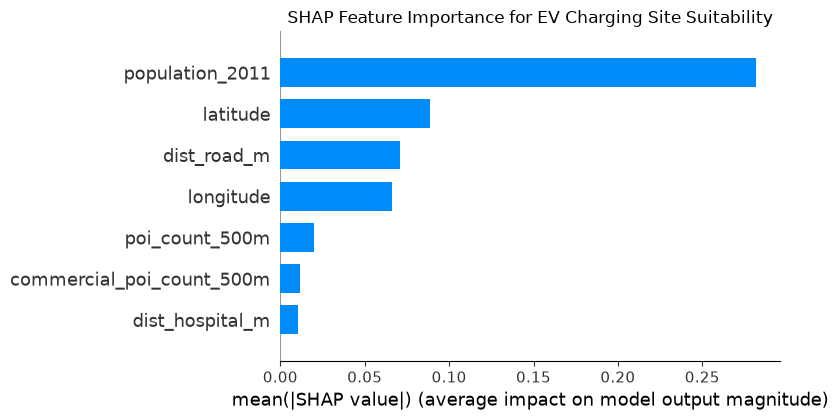

SUCCESS
SHAP plot saved at:
C:\Users\jamad\Documents\geosense\outputs\reports\shap_importance.png


In [4]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import shap
from pathlib import Path

project_root = Path(r"C:\Users\jamad\Documents\geosense")

data_path = project_root / "data" / "processed" / "labelled_sites.csv"
model_path = project_root / "models" / "site_suitability_model.pkl"
scaler_path = project_root / "models" / "site_feature_scaler.pkl"
feature_path = project_root / "models" / "site_feature_list.pkl"

report_dir = project_root / "outputs" / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path)

feature_cols = joblib.load(feature_path)
model = joblib.load(model_path)
scaler = joblib.load(scaler_path)

X = df[feature_cols].copy()
X_scaled = scaler.transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_scaled_df)

if isinstance(shap_values, list):
    shap_values_for_good_site = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_values_for_good_site = shap_values[:, :, 1]
else:
    shap_values_for_good_site = shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values_for_good_site,
    X_scaled_df,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance for EV Charging Site Suitability")
plt.tight_layout()

output_file = report_dir / "shap_importance.png"
plt.savefig(output_file, dpi=200, bbox_inches="tight")
plt.show()

print("SUCCESS")
print("SHAP plot saved at:")
print(output_file)

In [1]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from xgboost import XGBClassifier

project_root = Path(r"C:\Users\jamad\Documents\geosense")

data_path = project_root / "data" / "processed" / "labelled_sites.csv"

df = pd.read_csv(data_path)

feature_cols = [
    "latitude",
    "longitude",
    "population_2011",
    "dist_road_m",
    "dist_traffic_m",
    "dist_hospital_m",
    "dist_market_m",
    "building_count_500m",
    "poi_count_500m",
    "commercial_poi_count_500m",
    "elevation_m",
    "slope_deg",
    "flood_risk_proxy",
    "land_use_class",
]

X = df[feature_cols].copy()
y = df["label"].astype(int)

X = pd.get_dummies(
    X,
    columns=["flood_risk_proxy", "land_use_class"],
    dummy_na=True
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(y_test, xgb_predictions)
xgb_precision = precision_score(y_test, xgb_predictions)
xgb_recall = recall_score(y_test, xgb_predictions)
xgb_f1 = f1_score(y_test, xgb_predictions)

print("=" * 65)
print("XGBOOST MODEL RESULTS")
print("=" * 65)

print(f"\nXGBoost test accuracy:  {xgb_accuracy:.3f}")
print(f"XGBoost precision:      {xgb_precision:.3f}")
print(f"XGBoost recall:         {xgb_recall:.3f}")
print(f"XGBoost F1-score:       {xgb_f1:.3f}")

print("\nClassification report:")
print(classification_report(y_test, xgb_predictions))

print("=" * 65)
print("MODEL COMPARISON")
print("=" * 65)
print("Random Forest test accuracy: 0.935")
print(f"XGBoost test accuracy:       {xgb_accuracy:.3f}")

if xgb_accuracy > 0.935:
    print("\nBest model: XGBoost")
else:
    print("\nBest model: Random Forest")

XGBOOST MODEL RESULTS

XGBoost test accuracy:  0.990
XGBoost precision:      0.981
XGBoost recall:         1.000
XGBoost F1-score:       0.991

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        96
           1       0.98      1.00      0.99       105

    accuracy                           0.99       201
   macro avg       0.99      0.99      0.99       201
weighted avg       0.99      0.99      0.99       201

MODEL COMPARISON
Random Forest test accuracy: 0.935
XGBoost test accuracy:       0.990

Best model: XGBoost
